# JWT (JSON Web Tokens)

A JWT is a compact, URL-safe means of representing claims to be transferred between two parties. It consists of three parts separated by dots (.):
1. **Header**: Algorithm & Token Type (e.g., `{"alg": "HS256", "typ": "JWT"}`).
1. **Payload**: Data (Claims) about the user (e.g., `{"id": 123, "role": "admin"}`).
1. **Signature**: Verifies the token hasn't been tampered with.

**The Flow**:
1. User logs in with credentials.
1. Server verifies credentials and returns a **signed JWT**.
1. Client stores the JWT (e.g., in cookies).
1. Client sends the JWT in the `Authorization` header (`Bearer <token>`) for subsequent requests.
1. Server validates the signature and grants access.

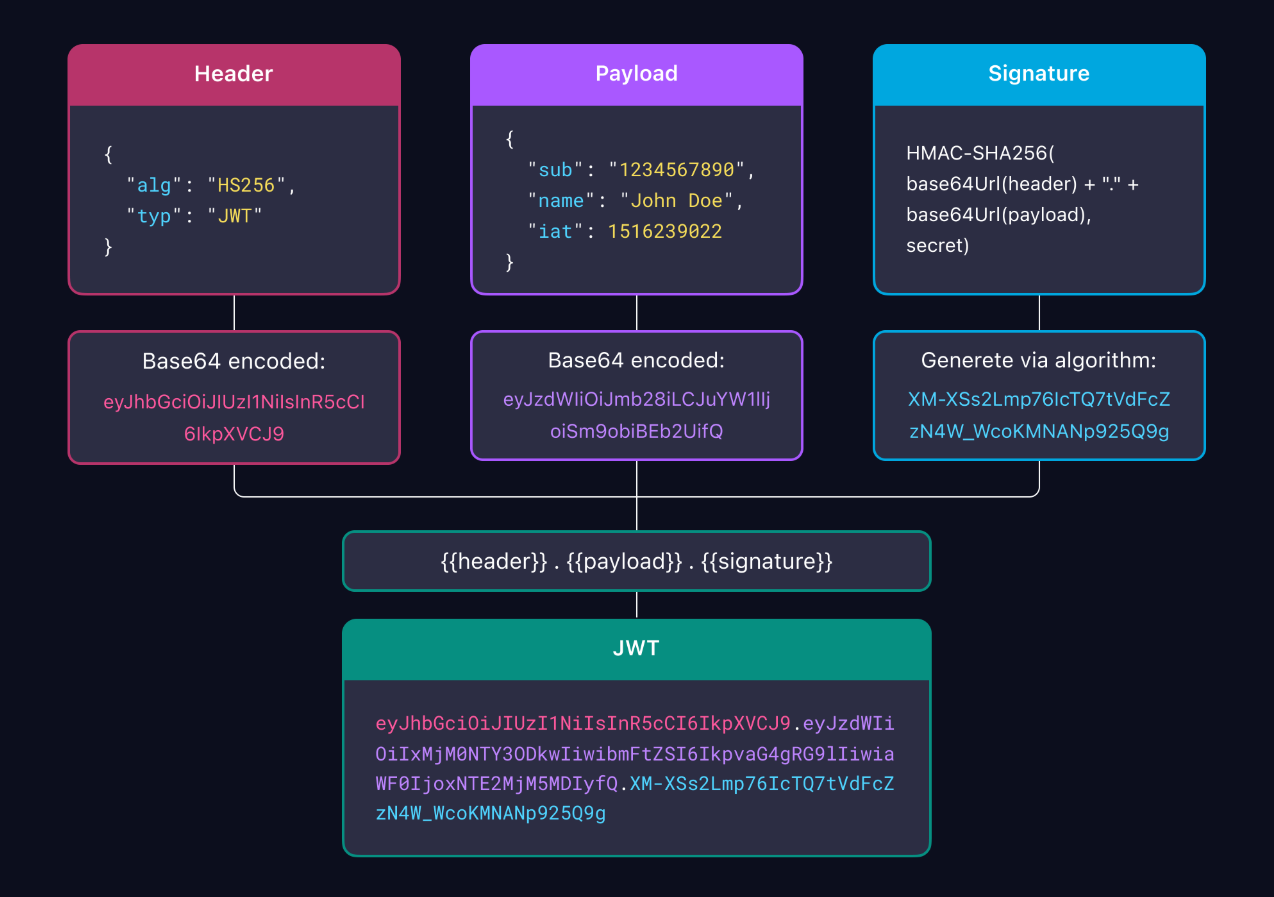

# Refresh Tokens & Security Best Practices

In a real-world application, keeping an Access Token valid for a long time (e.g., 1 week) is a security risk. If it's stolen, the attacker has access for that entire week. However, asking the user to log in every 15 minutes is a bad user experience.

**The Solution: Access Token + Refresh Token**
1. **Access Token**: Short-lived (e.g., 15 minutes). Used for API requests.
1. **Refresh Token**: Long-lived (e.g., 7 days). Stored securely (e.g., HTTPOnly cookie). Used ONLY to get a new Access Token.


**The Flow with Refresh Tokens:**
1. Client makes an API request with Access Token.
1. If server returns `401 Unauthorized` (Token Expired), client sends the Refresh Token to a special endpoint (e.g., `/auth/refresh`).
1. Server validates the Refresh Token and issues a new Access Token.
1. Client retries the original request with the new Access Token.

**NOTE**: NEVER store sensitive data (like passwords or credit card numbers) in a JWT. JWTs are encoded (Base64), not encrypted.


```python
import jwt
import datetime

SECRET_KEY = "my_super_secret_key"

def create_token(user_id):
    payload = {
        "user_id": user_id,
        "exp": datetime.datetime.utcnow() + datetime.timedelta(hours=1)
    }
    token = jwt.encode(payload, SECRET_KEY, algorithm="HS256")
    return token

def verify_token(token):
    try:
        payload = jwt.decode(token, SECRET_KEY, algorithms=["HS256"])
        return payload["user_id"]
    except jwt.ExpiredSignatureError:
        return "Token expired"
    except jwt.InvalidTokenError:
        return "Invalid token"
```

# Rate Limiting

Imagine a user (or a bot) sending 10,000 requests per second to your login endpoint. This could crash your database or slow down the service for everyone else.

**Rate Limiting** controls the number of requests a client can make within a specific timeframe (e.g., 100 requests per minute). It protects against:
- **DDoS Attacks**: Overwhelming the server.
- **Brute Force Attacks**: Guessing passwords.
- **Resource Starvation**: Ensuring fair usage for all users.

Strategies:
1. **Fixed Window**: "100 requests per hour". The counter resets at the top of the hour. Simple but can have "burst" issues at the window boundary.
1. **Sliding Window**: Smoother approach, calculating the rate based on the last X minutes.
1. **Token Bucket**: Analogy of a bucket filled with tokens at a constant rate. Each request costs a token. If the bucket is empty, the request is rejected (429 Too Many Requests).

# API Documentation

FastAPI do support web base documentation via Swagger UI